# Hw2.1 — Знайомство з Pandas
Коефіцієнт народжуваності в регіонах України (1950—2019)

In [1]:
import io, re
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", palette="viridis")

## 1. Читання даних через `read_html`

In [2]:
URL = "https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8"

def load_html(src):
    """Повертає HTML-текст сторінки (з URL або з локального файлу)."""
    if src.startswith("http"):
        r = requests.get(src, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
        r.raise_for_status()
        return r.text
    with open(src, encoding="utf-8") as f:
        return f.read()

def flatten_cols(df):
    """Якщо заголовок багаторівневий - склеюємо рівні в один рядок."""
    df = df.copy()
    df.columns = [" ".join(dict.fromkeys(map(str, c))) if isinstance(c, tuple) else str(c)
                  for c in df.columns]
    return df

tables = [flatten_cols(t) for t in pd.read_html(io.StringIO(load_html(URL)), thousands=None, decimal=",")]

def is_target(t):
    return (any("1950" in c for c in t.columns)
            and any("2019" in c for c in t.columns)
            and len(t) >= 20
            and t.iloc[:, 0].astype(str).str.contains("Вінницька").any())

candidates = [i for i, t in enumerate(tables) if is_target(t)]
print("Знайдено таблиць-кандидатів:", candidates)
df = tables[candidates[0]].copy()

Знайдено таблиць-кандидатів: [12]


## 2. Перші рядки та розмір таблиці

In [3]:

df.columns = [re.sub(r"\[.*?\]", "", c).strip() for c in df.columns]
df = df.rename(columns={df.columns[0]: "Регіон"})
df.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—


In [4]:
print("Кількість рядків та стовпців:", df.shape)

Кількість рядків та стовпців: (28, 9)


## 3. Заміна «—» на NaN

In [5]:
df = df.replace(r"^\s*[—–−-]\s*$", np.nan, regex=True)
df.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,NaN,NaN
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,NaN


## 4. Типи стовпців

In [6]:
df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,float64
2000,float64
2012,float64
2014,object
2019,object


Стовпці, де був символ «—», мають тип `object` (рядки), тому їх треба перетворити на числові.

In [7]:
year_cols = list(df.columns[1:])
for col in year_cols:
    cleaned = (df[col].astype(str)
                      .str.replace(r"\[.*?\]", "", regex=True)
                      .str.replace("\xa0", "", regex=False)
                      .str.replace(",", ".", regex=False)
                      .str.strip())
    df[col] = pd.to_numeric(cleaned, errors="coerce")

df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,float64
2000,float64
2012,float64
2014,float64
2019,float64


## 5. Частка пропусків у кожній стовпці

In [8]:
missing_count = df.isnull().sum()
missing_share = missing_count / len(df)
pd.DataFrame({"пропусків": missing_count, "частка": missing_share.round(3)})

,пропусків,частка
Регіон,0,0.000
1950,2,0.071
1960,1,0.036
1970,1,0.036
1990,0,0.000
2000,0,0.000
2012,0,0.000
2014,2,0.071
2019,4,0.143


## 6. Видалення рядка по всій країні (останній рядок)

In [9]:
def ycol(year):
    """Назва стовпця за роком."""
    return next(c for c in year_cols if str(year) in c)

print("Останній рядок:", df.iloc[-1, 0])
national_2019 = df.iloc[-1][ycol(2019)]
print("Народжуваність по Україні у 2019:", national_2019)

df = df.iloc[:-1].reset_index(drop=True)
df.shape

Останній рядок: Україна
Народжуваність по Україні у 2019: 8.1


(27, 9)

## 7. Заповнення пропусків середніми значеннями стовпців

In [10]:
df[year_cols] = df[year_cols].fillna(df[year_cols].mean())
print("Залишилось пропусків:", df.isnull().sum().sum())
df.head()

Залишилось пропусків: 0


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,11.144,8.017391
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.900,7.600000
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.100,10.100000
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.100,7.100000
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.200,8.017391


## 8. Регіони, де народжуваність у 2019 була вищою за середню по Україні

In [11]:
above = df[df[ycol(2019)] > national_2019][["Регіон", ycol(2019)]]
print(f"Середнє по Україні: {national_2019}")
above.sort_values(ycol(2019), ascending=False)

Середнє по Україні: 8.1


,Регіон,2019
25,Київ,11.0
16,Рівненська,10.7
6,Закарпатська,10.4
2,Волинська,10.1
23,Чернівецька,9.2
8,Івано-Франківська,8.8
14,Одеська,8.8
12,Львівська,8.7


## 9. Регіон з найвищою народжуваністю у 2014 році

In [12]:
best_2014 = df.loc[df[ycol(2014)].idxmax()]
print(f"Найвища народжуваність у 2014: {best_2014['Регіон']} ({best_2014[ycol(2014)]})")

Найвища народжуваність у 2014: Рівненська (14.8)


## 10. Стовпчикова діаграма народжуваності по регіонах у 2019

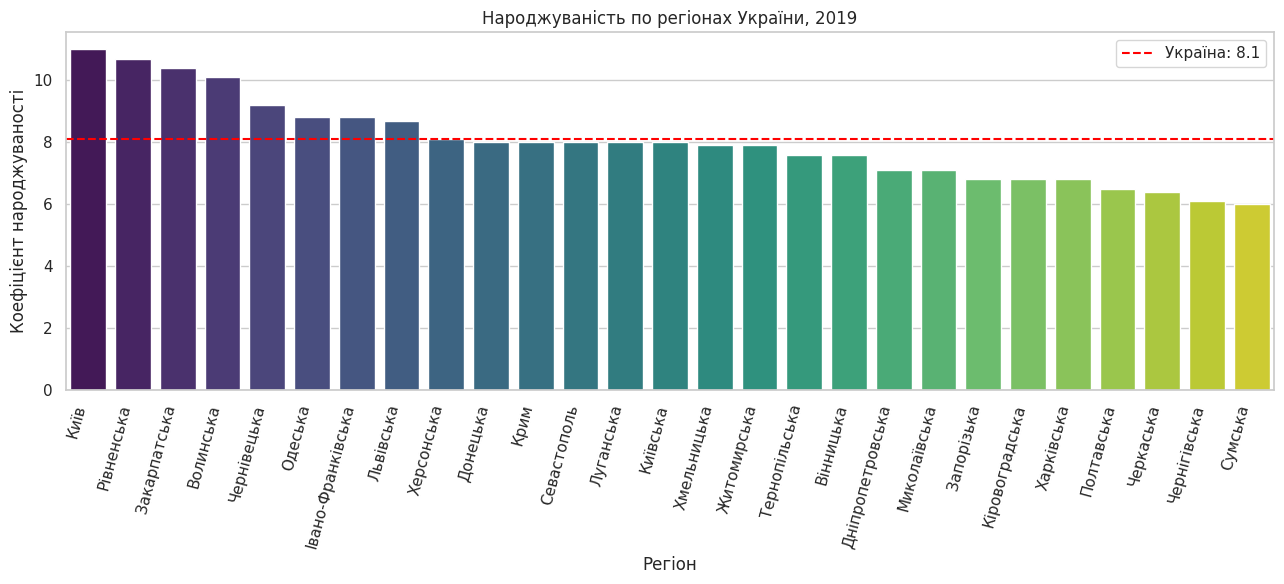

In [13]:
d = df.sort_values(ycol(2019), ascending=False)
plt.figure(figsize=(13, 6))
sns.barplot(data=d, x="Регіон", y=ycol(2019), hue="Регіон", palette="viridis", legend=False)
plt.axhline(national_2019, color="red", linestyle="--", label=f"Україна: {national_2019}")
plt.xticks(rotation=75, ha="right")
plt.title("Народжуваність по регіонах України, 2019")
plt.ylabel("Коефіцієнт народжуваності")
plt.legend()
plt.tight_layout()
plt.show()

---
## Візуалізація (додаткові графіки)

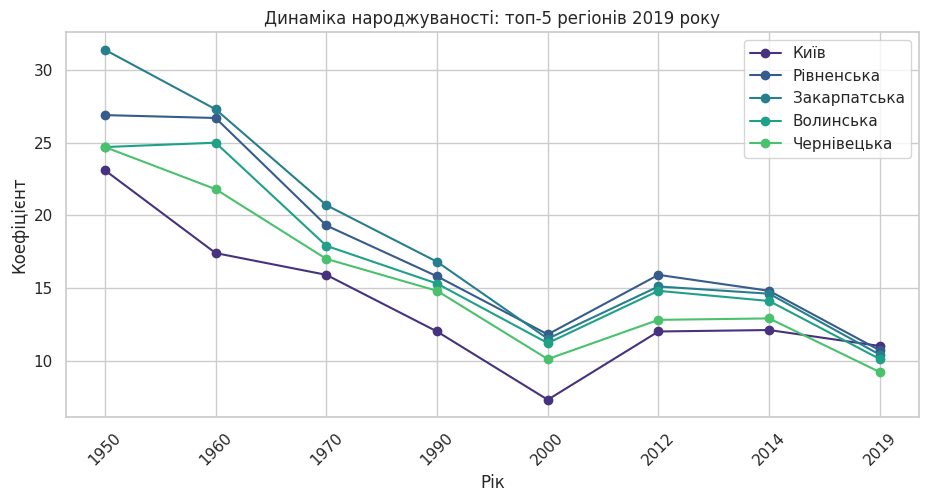

In [14]:

top5 = df.nlargest(5, ycol(2019))
plt.figure(figsize=(11, 5))
for _, row in top5.iterrows():
    plt.plot(year_cols, row[year_cols].astype(float), marker="o", label=row["Регіон"])
plt.title("Динаміка народжуваності: топ-5 регіонів 2019 року")
plt.xlabel("Рік"); plt.ylabel("Коефіцієнт")
plt.xticks(rotation=45)
plt.legend()
plt.show()

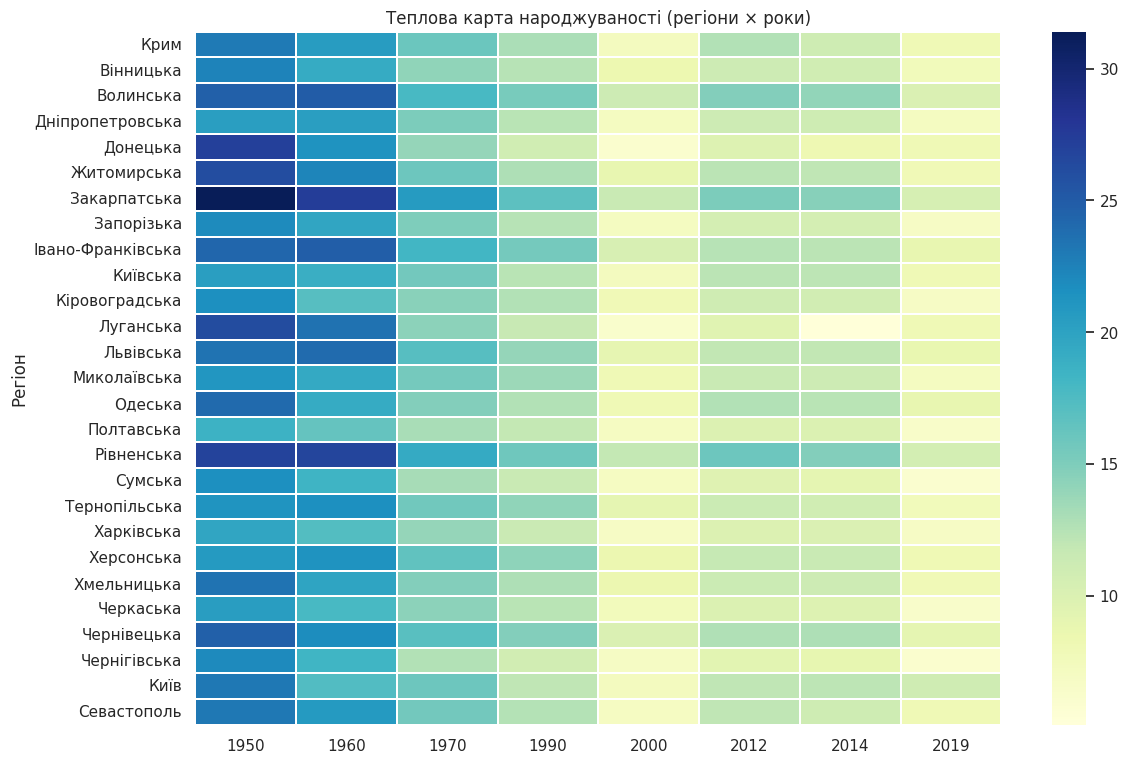

In [15]:

plt.figure(figsize=(13, 9))
sns.heatmap(df.set_index("Регіон")[year_cols], cmap="YlGnBu", annot=False, linewidths=.3)
plt.title("Теплова карта народжуваності (регіони × роки)")
plt.show()

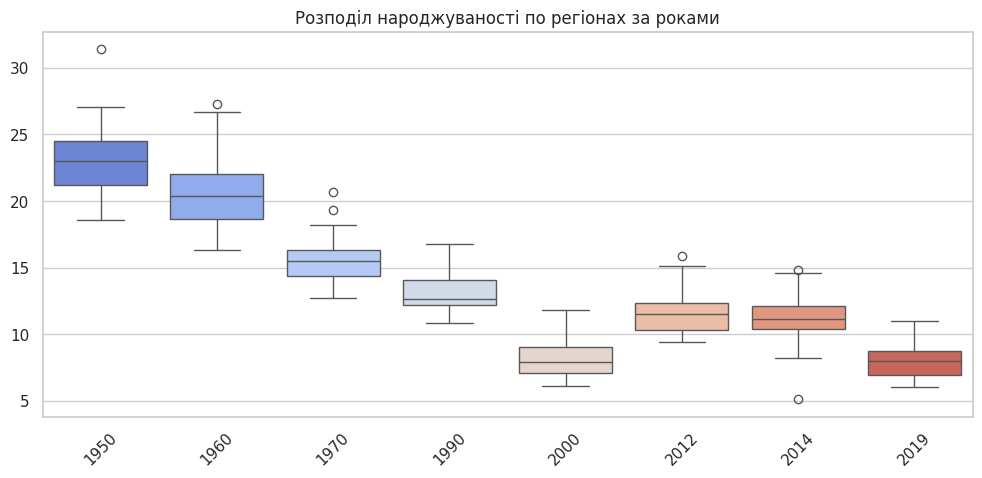

In [16]:

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[year_cols], palette="coolwarm")
plt.xticks(rotation=45)
plt.title("Розподіл народжуваності по регіонах за роками")
plt.show()

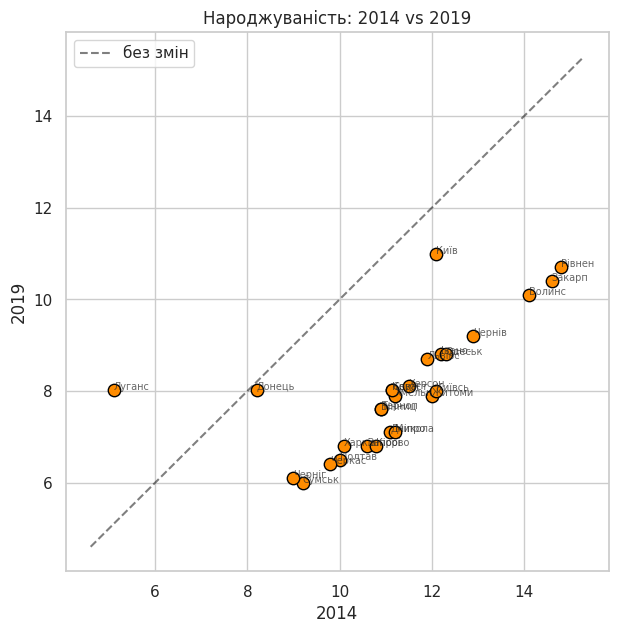

In [17]:

plt.figure(figsize=(7, 7))
plt.scatter(df[ycol(2014)], df[ycol(2019)], c="darkorange", edgecolor="black", s=80)
lims = [min(df[ycol(2014)].min(), df[ycol(2019)].min()) - .5, max(df[ycol(2014)].max(), df[ycol(2019)].max()) + .5]
plt.plot(lims, lims, "k--", alpha=.5, label="без змін")
for _, r in df.iterrows():
    plt.annotate(r["Регіон"][:6], (r[ycol(2014)], r[ycol(2019)]), fontsize=7, alpha=.7)
plt.xlabel("2014"); plt.ylabel("2019")
plt.title("Народжуваність: 2014 vs 2019")
plt.legend()
plt.show()

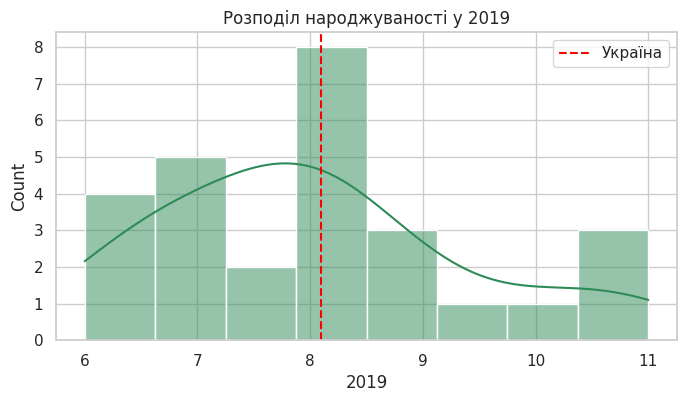

In [18]:

plt.figure(figsize=(8, 4))
sns.histplot(df[ycol(2019)], bins=8, kde=True, color="seagreen")
plt.axvline(national_2019, color="red", linestyle="--", label="Україна")
plt.title("Розподіл народжуваності у 2019")
plt.legend()
plt.show()